# Demo: flujo de delegación del orquestador multi-agente

Este notebook muestra al **Supervisor** delegando en el **Investigador** (búsqueda en la base vectorial de la pre-entrega 3), recibiendo el dato, enviándolo al **Analista** (cómputo), pasando por la **Validación** y cerrando con la **Síntesis**.

Requisitos: el entorno instalado (`pip install -r requirements.txt`) y una API key en `.env` (ver README). Se ejecuta desde la raíz del repo.

In [1]:
import logging, sys
from dotenv import load_dotenv

load_dotenv()
logging.basicConfig(level=logging.INFO, format='%(message)s', stream=sys.stdout, force=True)
for ruidoso in ('httpx', 'anthropic', 'openai', 'chromadb', 'sentence_transformers', 'huggingface_hub'):
    logging.getLogger(ruidoso).setLevel(logging.WARNING)

from graph import abrir_checkpointer, build_graph, modelo_llm, proveedor_llm, verificar_configuracion
from main import config_de, ejecutar_turno
from tools.custom_tools import ingestar

verificar_configuracion()
vectorstore = ingestar()  # idempotente: si la colección ya existe, no re-indexa
print('Proveedor:', proveedor_llm(), '· modelo del supervisor:', modelo_llm('supervisor'))

D:\AI-ENGINEERING-6\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2183.17it/s]

Colección 'plataforma_pedidos' ya poblada (36 fragmentos): se omite la ingesta.


Proveedor: anthropic · modelo del supervisor: claude-sonnet-5-5


## 1. El grafo

Generado con `graph.get_graph().draw_mermaid_png()`. Las flechas punteadas son aristas condicionales.

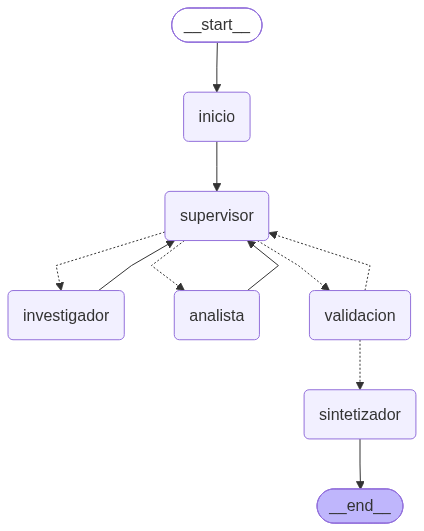

In [2]:
from IPython.display import Image, display

display(Image(build_graph(vectorstore=vectorstore).get_graph().draw_mermaid_png()))

## 2. Una consulta que obliga a delegar en los dos especialistas

La pregunta necesita **datos de la documentación** (umbral de alerta, límite del pool, runbook) y **cálculos** (porcentaje, margen, comparación). Cada línea `[paso N]` es una entrada de la bitácora `contribuciones` del estado: qué agente hizo qué.

In [3]:
DB, THREAD = 'checkpoints_notebook.db', 'notebook-demo'
PREGUNTA = ('Hoy PgBouncer tiene 87 conexiones activas sostenidas hace 3 minutos. ¿Ya debería haber '
            'saltado la alerta del pool? ¿A qué porcentaje del límite estamos y cuánto margen queda?')

async with abrir_checkpointer(DB) as saver:
    await saver.adelete_thread(THREAD)  # arranca de cero
    graph = build_graph(saver, vectorstore=vectorstore)
    turno = await ejecutar_turno(graph, THREAD, PREGUNTA)


[notebook-demo] Usuario: Hoy PgBouncer tiene 87 conexiones activas sostenidas hace 3 minutos. ¿Ya debería haber saltado la alerta del pool? ¿A qué porcentaje del límite estamos y cuánto margen queda?


  [paso 1] inicio → recibió la pregunta: Hoy PgBouncer tiene 87 conexiones activas sostenidas hace 3 minutos. ¿Ya debería haber saltado la alerta del pool? ¿A qué porcentaje del límite estamos y cuánto margen queda? (0.0s)


HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


  [paso 2] supervisor → delegó a investigador: Todavía no hay hallazgos: faltan el límite de conexiones del pool de PgBouncer y el umbral y la duración de la alerta, que están en la documentación. Primero debe intervenir el investigador; después el analista calculará porcentaje y margen. → instrucción: Buscá en la documentación interna (arquitectura, monitoreo y alertas, runbook) los siguientes datos sobre PgBouncer / pool de conexiones de la Plataforma de Pedidos: (1) el límite máximo de conexiones del pool (por ejemplo max_client_conn, default_pool_size o el valor que figure como límite); (2) la regla de alerta del pool: umbral (en porcentaje o en número de conexiones), duración sostenida requerida antes de disparar, y severidad; (3) cualquier acción recomendada del runbook cuando se dispara esa alerta. Devolvé cada dato con su fuente. Contexto: el usuario informa que hoy hay 87 conexiones activas sostenidas desde hace 3 minutos, y quiere saber si la alerta ya debería haber saltado. 

HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


...

  [paso 8] supervisor → envió a validación: decidió finalizar: La pregunta central está respondida con fuente y cálculos verificados: 87% de uso, 13 conexiones de margen, 7 por encima del umbral del 80% y 3 min contra los 2 requeridos. Los datos que marca la validación (max_client_conn y default_pool_size, severidad de la regla, intervalo de evaluación) ya figuran como 'sin información' o 'no declarado' en la documentación, así que otra búsqueda no los conseguiría. Se informan como limitaciones y supuestos. (6.48s)


  [paso 9] validacion → aprobó con limitaciones: Al análisis le faltan datos: Los parámetros max_client_conn y default_pool_size no aparecen por nombre en la documentación, por lo que no se puede verificar a qué parámetro corresponde el límite de 100.; La documentación no declara la severidad de la regla del 80% sostenido, así que no se sabe si genera solo un mensaje en Slack o también una llamada de PagerDuty.; El umbral figura solo en porcentaje; las 80 conexiones son una conversión hecha con el límite de 100, no un dato documentado.; No se indica el intervalo de evaluación de la alerta ni la ventana de medición exacta, lo que puede influir en el momento en que debería saltar.. (0.0s)


HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


  [paso 10] sintetizador → redactó la respuesta final: **Sí, la alerta ya debería haber saltado**, siempre que las 87 conexiones se hayan mantenido sin interrupción.

**Cuentas**
- Uso del pool: 87 / 100 × 100 = **8 (5.29s)



Respuesta: **Sí, la alerta ya debería haber saltado**, siempre que las 87 conexiones se hayan mantenido sin interrupción.

**Cuentas**
- Uso del pool: 87 / 100 × 100 = **87%** del límite de 100 conexiones por instancia [arquitectura_sistema.md].
- Umbral de alerta: 80% sostenido más de 2 minutos [monitoreo_alertas.md]. 100 × 80 / 100 = 80 conexiones.
- Sobre el umbral: 87 − 80 = **7 conexiones** (7 puntos porcentuales). Y 3 min > 2 min, o sea 1 minuto de sobra.
- Margen hasta el límite: 100 − 87 = **13 conexiones** (13 puntos porcentuales).

**Contexto**
Esta alerta es el precursor directo del Incidente 1 (agotamiento del pool), de criticidad alta [monitoreo_alertas.md] [runbook_incidentes.md]. Con 13 conexiones de margen estamos cerca del agotamiento.

**Qué indica el runbook** [runbook_incidentes.md]
1. Revisar en el dashboard de PgBouncer las conexiones activas vs. el límite (100).
2. Si hay queries colgadas, identificarlas con `SELECT * FROM pg_stat_activity WHERE state = 'active'

## 3. El orden de la delegación

In [4]:
print(' → '.join(p['agente'] for p in turno['pasos']))
print('Delegaciones:', turno['delegaciones'], '· rechazos de la validación:', turno['rechazos_validacion'])

inicio → supervisor → investigador → supervisor → analista → supervisor → validacion → supervisor → validacion → sintetizador
Delegaciones: {'investigador': 1, 'analista': 1} · rechazos de la validación: 1


## 4. Qué dejó cada especialista en su parcela del estado

El investigador escribe solo en `investigaciones` y el analista solo en `analisis`. Las fuentes salen de la metadata de Chroma (no del LLM) y cada cálculo del analista se re-evalúa en código.

In [5]:
async with abrir_checkpointer(DB) as saver:
    estado = (await build_graph(saver, vectorstore=vectorstore).aget_state(config_de(THREAD))).values

inv = estado['investigaciones'][-1]
print('INVESTIGADOR · fuentes consultadas:', inv.fuentes_consultadas)
for h in inv.resultado.hallazgos:
    print(f'  - {h.dato}  [{h.fuente}]')

an = estado['analisis'][-1]
print('\nANALISTA ·', an.resultado.resumen)
for c, v in zip(an.resultado.calculos, an.verificaciones):
    print(f"  - {c.descripcion}: {c.expresion} = {c.resultado}  (verificado en código: {'ok' if v.ok else v.detalle})")

INVESTIGADOR · fuentes consultadas: ['arquitectura_sistema.md', 'monitoreo_alertas.md', 'runbook_incidentes.md']
  - Límite del pool: 100 conexiones por instancia, con PgBouncer en modo `transaction`.  [arquitectura_sistema.md]
  - Los parámetros max_client_conn y default_pool_size no aparecen por nombre en la documentación recuperada: sin información.  [arquitectura_sistema.md]
  - Conexiones activas vs. límite configurado (100). Alerta al superar el 80% de uso sostenido durante más de 2 minutos; es el precursor directo del Incidente 1 del runbook (agotamiento del pool de conexiones). El umbral se da solo en porcentaje, no en número de conexiones.  [monitoreo_alertas.md]
  - Las alertas de severidad alta (ej. tasa de 5xx elevada, pool de PostgreSQL agotado) van a Slack (#alertas-produccion) y a llamada telefónica automática al ingeniero de guardia vía PagerDuty; las de severidad media y baja solo a Slack. La regla del 80% sostenido no declara explícitamente su propia severidad.  [moni

## 5. Respuesta final (fase de síntesis)

In [6]:
print(estado['respuesta_final'])

**Sí, la alerta ya debería haber saltado**, siempre que las 87 conexiones se hayan mantenido sin interrupción.

**Cuentas**
- Uso del pool: 87 / 100 × 100 = **87%** del límite de 100 conexiones por instancia [arquitectura_sistema.md].
- Umbral de alerta: 80% sostenido más de 2 minutos [monitoreo_alertas.md]. 100 × 80 / 100 = 80 conexiones.
- Sobre el umbral: 87 − 80 = **7 conexiones** (7 puntos porcentuales). Y 3 min > 2 min, o sea 1 minuto de sobra.
- Margen hasta el límite: 100 − 87 = **13 conexiones** (13 puntos porcentuales).

**Contexto**
Esta alerta es el precursor directo del Incidente 1 (agotamiento del pool), de criticidad alta [monitoreo_alertas.md] [runbook_incidentes.md]. Con 13 conexiones de margen estamos cerca del agotamiento.

**Qué indica el runbook** [runbook_incidentes.md]
1. Revisar en el dashboard de PgBouncer las conexiones activas vs. el límite (100).
2. Si hay queries colgadas, identificarlas con `SELECT * FROM pg_stat_activity WHERE state = 'active' ORDER BY qu

## 6. Seguimiento en el mismo `thread_id`

El checkpointer SQLite (pre-entrega 5) guarda el estado: "esas conexiones" se resuelve con la conversación previa, que el supervisor incluye en la instrucción autocontenida que le da a cada especialista.

In [7]:
async with abrir_checkpointer(DB) as saver:
    graph = build_graph(saver, vectorstore=vectorstore)
    seguimiento = await ejecutar_turno(
        graph, THREAD, 'Si subimos temporalmente el límite como indica el runbook, ¿a qué porcentaje quedarían esas conexiones?'
    )


[notebook-demo] Usuario: Si subimos temporalmente el límite como indica el runbook, ¿a qué porcentaje quedarían esas conexiones?


  [paso 1] inicio → recibió la pregunta: Si subimos temporalmente el límite como indica el runbook, ¿a qué porcentaje quedarían esas conexiones? (0.0s)


HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


  [paso 2] supervisor → delegó a investigador: Falta confirmar con fuente en la documentación el valor del límite temporal que indica el runbook y el umbral de alerta, antes de calcular el porcentaje. En este turno todavía no hay hallazgos ni cálculos. → instrucción: Buscá en la documentación (runbook_incidentes.md, arquitectura_sistema.md, monitoreo_alertas.md) lo siguiente sobre PgBouncer y el Incidente 1 (agotamiento del pool): 1) a qué valor indica el runbook subir temporalmente el límite de conexiones cuando el problema es solo de volumen (se recuerda 150, confirmalo); 2) cuál es el límite actual de conexiones por instancia (se recuerda 100); 3) cuál es el umbral de la alerta del pool (se recuerda 80% sostenido más de 2 minutos) y si está definido como porcentaje del límite configurado. Devolvé cada dato con su fuente. Contexto: el usuario tiene 87 conexiones activas en PgBouncer y pregunta a qué porcentaje quedarían si se sube el límite como indica el runbook. No calcules. (7.0s)

HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


...

  [paso 8] supervisor → envió a validación: decidió finalizar: El analista calculó con verificación correcta que 87 conexiones sobre un límite de 150 dan 58% de uso, con 63 conexiones de margen. Los dos datos faltantes que marcó la validación, si el umbral se recalcula contra el nuevo límite y cuántas instancias hay, ya fueron buscados por el investigador y no figuran en la documentación. Se informan como supuestos y limitaciones, sin volver a delegar. (6.33s)


  [paso 9] validacion → aprobó con limitaciones: Al análisis le faltan datos: La documentación no indica si el umbral de alerta se reconfigura automáticamente al cambiar el límite de conexiones; solo lo define como porcentaje del 'límite configurado' con 100 como referencia.; No se indica la cantidad de instancias de PgBouncer; el límite de 100 (y el de 150) es por instancia y el runbook también ofrece escalar réplicas como alternativa.. (0.0s)


HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


  [paso 10] sintetizador → redactó la respuesta final: **Con el límite en 150, las 87 conexiones quedarían en 58% de uso.**

**Cuentas**
- Uso: 87 / 150 × 100 = **58%**. Hoy estamos en 87%, así que baja 87 − 58 = ** (4.52s)



Respuesta: **Con el límite en 150, las 87 conexiones quedarían en 58% de uso.**

**Cuentas**
- Uso: 87 / 150 × 100 = **58%**. Hoy estamos en 87%, así que baja 87 − 58 = **29 pp**.
- Umbral de alerta (80% del nuevo límite): 150 × 0,8 = 120 conexiones. Faltarían 120 − 87 = **33 conexiones** para llegar. Con el límite actual el umbral es 100 × 0,8 = 80 [monitoreo_alertas.md].
- Margen: 150 − 87 = **63 conexiones** libres (antes 13, o sea +50). En puntos porcentuales: 100 − 58 = **42 pp** (antes 13).
- Con 58% quedaríamos 22 pp por debajo del umbral del 80%.

**Contexto**
El runbook indica subir temporalmente el límite a 150 si el problema es puramente de volumen, sin queries colgadas [runbook_incidentes.md]. El límite actual es 100 por instancia [arquitectura_sistema.md], y la alerta se define como porcentaje del límite configurado [monitoreo_alertas.md].

Limitaciones: la documentación no confirma que la alerta se recalcule contra 150 tras el cambio. Si siguiera calculándose contra 100,